# Avaliação de baselines e primeiro agente PPO

Este notebook executa o simulador reproduzível do projeto, grava os resultados por jogador/partida e cria gráficos para comparar vitórias, truncagens e patrimônio. O conjunto inicial usa partidas de dois jogadores; ajuste `N_GAMES` para 500 ao fazer uma avaliação final.

A seção de PPO é opcional. O treinador experimental já está no repositório, mas a construção das observações é pesada: numa medição local, uma partida limitada a 20 turnos levou cerca de 29 segundos em modo sem gráficos. Comece com poucas partidas e aumente o volume depois de medir o tempo no seu ambiente. As baselines existentes recusam propostas recebidas; portanto, este primeiro treino ainda não ensina negociação.

In [2]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Abra o notebook dentro do repositório Monopoly-AI.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUTPUT_DIR = ROOT / "runs" / "evaluation_notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Repositório: {ROOT}")
print(f"Resultados: {OUTPUT_DIR}")

Repositório: /media/marth/Dados/Arquivos/Monopoly-AI
Resultados: /media/marth/Dados/Arquivos/Monopoly-AI/runs/evaluation_notebook


In [3]:
# Para uma análise exploratória use 50–100 partidas; para o teste final, use 500.
N_GAMES = 50
BASE_SEED = 2026
MAX_TURNS_2P = 1000

SCENARIOS = [
    ("random × greedy:0", ["random", "greedy:0"], MAX_TURNS_2P),
    ("greedy:0 × greedy:25", ["greedy:0", "greedy:25"], MAX_TURNS_2P),
    ("greedy:25 × greedy:50", ["greedy:25", "greedy:50"], MAX_TURNS_2P),
    ("greedy:25 × greedy:150", ["greedy:25", "greedy:150"], MAX_TURNS_2P),
]

# Ative para acrescentar o cenário multi-jogador. O histórico do projeto mostrou
# alta truncagem em quatro jogadores mesmo com limite de 3000 turnos.
INCLUDE_FOUR_PLAYER = False
if INCLUDE_FOUR_PLAYER:
    SCENARIOS.append((
        "4 jogadores: greedy:25 × 3 greedy:150",
        ["greedy:25", "greedy:150", "greedy:150", "greedy:150"],
        3000,
    ))

print(f"{len(SCENARIOS)} cenários; {N_GAMES} partidas por cenário")

4 cenários; 50 partidas por cenário


In [4]:
RUN_SIMULATIONS = True  # False reutiliza os CSVs já gravados.
runs = []
for index, (scenario, policies, max_turns) in enumerate(SCENARIOS):
    csv_path = OUTPUT_DIR / f"scenario_{index + 1}.csv"
    command = [
        sys.executable, "-m", "app.envs.simulate",
        "--games", str(N_GAMES),
        "--policies", *policies,
        "--seed", str(BASE_SEED),
        "--max-turns", str(max_turns),
        "--csv", str(csv_path),
    ]
    if RUN_SIMULATIONS:
        result = subprocess.run(command, cwd=ROOT, check=True, text=True, capture_output=True)
        print(f"\n### {scenario}\n{result.stdout}")
    else:
        print(f"\n### {scenario}\nReutilizando {csv_path}")
    frame = pd.read_csv(csv_path)
    frame["scenario"] = scenario
    runs.append(frame)

results = pd.concat(runs, ignore_index=True)
print(f"\nLinhas individuais salvas: {len(results):,}")


### random × greedy:0
50 partidas | 2 jogadores | seeds 2026–2075
0.0% truncadas | 0.0% sem vencedor | 66.3 turnos médios | 3,806 ações/s | 7.4s
random (50 assentos) : resultado por partida: W–L–D 0–50–0 em 50 partidas (0.0%; IC95% 0.0%–7.1%; 0.0% nas decididas; 0 truncadas) | vitórias por assento 0/50 (0.0%) | falências 100.0% | caixa médio 0 | patrimônio médio 0 | imóveis médios 0.0
greedy:0 (50 assentos) : resultado por partida: W–L–D 50–0–0 em 50 partidas (100.0%; IC95% 92.9%–100.0%; 100.0% nas decididas; 0 truncadas) | vitórias por assento 50/50 (100.0%) | falências 0.0% | caixa médio 46 | patrimônio médio 4813 | imóveis médios 22.8
resultados por jogador/partida: /media/marth/Dados/Arquivos/Monopoly-AI/runs/evaluation_notebook/scenario_1.csv


### greedy:0 × greedy:25
50 partidas | 2 jogadores | seeds 2026–2075
18.0% truncadas | 0.0% sem vencedor | 309.7 turnos médios | 4,406 ações/s | 14.8s
greedy:0 (50 assentos) : resultado por partida: W–L–D 22–19–0 em 50 partidas (44.0%; IC9

In [5]:
def wilson_interval(wins, games, z=1.96):
    if games == 0:
        return 0.0, 0.0
    rate = wins / games
    denom = 1 + z * z / games
    center = (rate + z * z / (2 * games)) / denom
    margin = z * np.sqrt(rate * (1 - rate) / games + z * z / (4 * games * games)) / denom
    return max(0.0, center - margin), min(1.0, center + margin)

# Um registro por grupo de política e partida: em quatro jogadores, três assentos
# Greedy contam como um grupo, sem triplicar o número de partidas.
match_rows = results.drop_duplicates(["scenario", "game_index", "policy"]).copy()
match_rows["group_won"] = match_rows["winner_policy"] == match_rows["policy"]
summary_rows = []
for (scenario, policy), group in match_rows.groupby(["scenario", "policy"], sort=False):
    games = len(group)
    wins = int(group["group_won"].sum())
    low, high = wilson_interval(wins, games)
    player_rows = results[(results["scenario"] == scenario) & (results["policy"] == policy)]
    summary_rows.append({
        "scenario": scenario, "policy": policy, "games": games,
        "win_rate": wins / games, "ci_low": low, "ci_high": high,
        "decided_rate": group["match_decided"].mean(),
        "truncation_rate": group["truncated"].mean(),
        "seat_win_rate": player_rows["won"].mean(),
        "mean_cash": player_rows["cash"].mean(),
        "mean_net_worth": player_rows["net_worth"].mean(),
        "mean_properties": player_rows["properties"].mean(),
    })
summary = pd.DataFrame(summary_rows)
summary
print(summary.to_string(index=False))

              scenario     policy  games  win_rate   ci_low  ci_high  decided_rate  truncation_rate  seat_win_rate  mean_cash  mean_net_worth  mean_properties
     random × greedy:0     random     50      0.00 0.000000 0.071350          1.00             0.00           0.00       0.00            0.00             0.00
     random × greedy:0   greedy:0     50      1.00 0.928650 1.000000          1.00             0.00           1.00      46.12         4813.12            22.76
  greedy:0 × greedy:25   greedy:0     50      0.44 0.311620 0.576942          0.82             0.18           0.44    3637.44         7273.14            13.74
  greedy:0 × greedy:25  greedy:25     50      0.38 0.258626 0.518498          0.82             0.18           0.38    2736.56         5772.96            11.50
 greedy:25 × greedy:50  greedy:25     50      0.42 0.293748 0.557668          0.86             0.14           0.42    2252.22         5349.72            11.94
 greedy:25 × greedy:50  greedy:50     50      

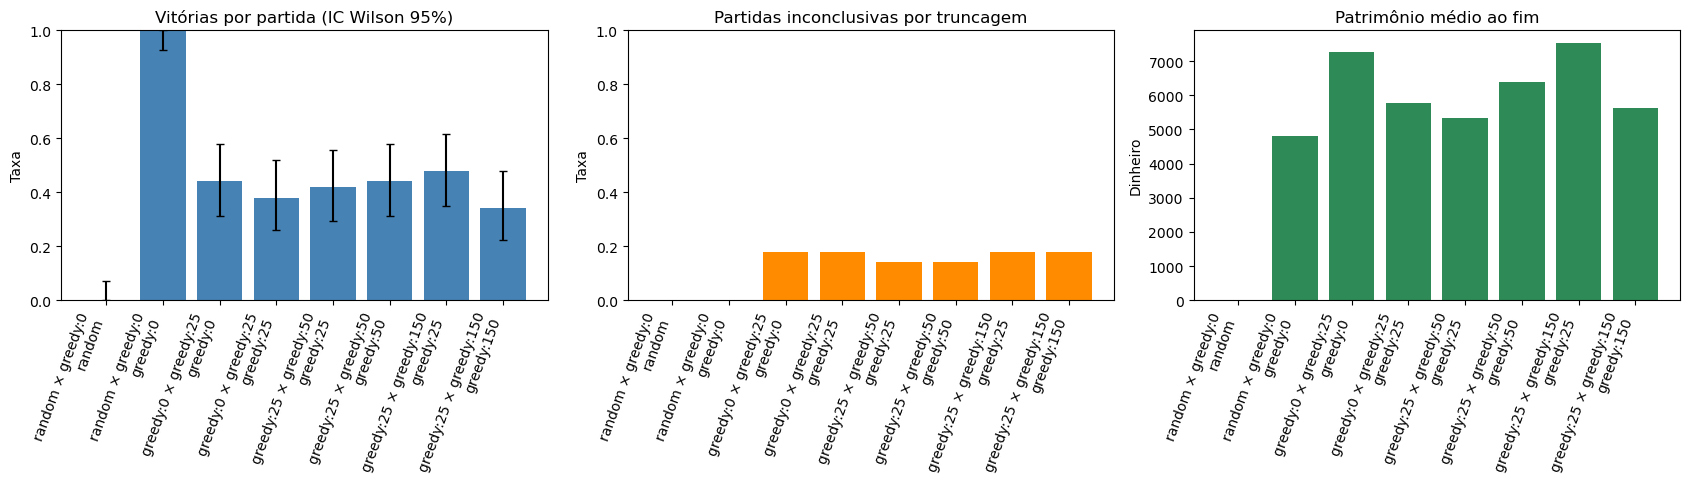

In [6]:
labels = [f"{row.scenario}\n{row.policy}" for row in summary.itertuples()]
x = np.arange(len(summary))
rate = summary["win_rate"].to_numpy()
low = summary["ci_low"].to_numpy()
high = summary["ci_high"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].bar(x, rate, color="steelblue")
axes[0].errorbar(x, rate, yerr=np.vstack((rate - low, high - rate)), fmt="none", color="black", capsize=3)
axes[0].set_title("Vitórias por partida (IC Wilson 95%)")
axes[0].set_ylabel("Taxa")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(x, labels, rotation=70, ha="right")

axes[1].bar(x, summary["truncation_rate"], color="darkorange")
axes[1].set_title("Partidas inconclusivas por truncagem")
axes[1].set_ylabel("Taxa")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(x, labels, rotation=70, ha="right")

axes[2].bar(x, summary["mean_net_worth"], color="seagreen")
axes[2].set_title("Patrimônio médio ao fim")
axes[2].set_ylabel("Dinheiro")
axes[2].set_xticks(x, labels, rotation=70, ha="right")
fig.tight_layout()
plt.show()

## Treino PPO (opcional)

`RUN_PPO` fica desligado por padrão para que a avaliação das baselines rode primeiro. Quando desligado, a célula informa isso explicitamente; altere-o para `True` para iniciar o treino. O treinador imprime o resultado de cada episódio e as avaliações periódicas. O exemplo abaixo usa poucas partidas e é apenas uma execução inicial; para uma avaliação válida, aumente o número de episódios, use os seeds reservados e compare pelo protocolo em `docs/contrato-avaliacao-agentes.md`. O primeiro treino usa `trade_analysis_mode="disabled"`, pois os oponentes atuais não ensinam respostas e propostas de troca.

A truncagem retorna recompensa zero; o treinador usa bootstrap do crítico no estado-limite, sem converter caixa ou patrimônio em recompensa.

In [ ]:
RUN_PPO = True
PPO_EPISODES = 8
PPO_MAX_TURNS = 1000
PPO_EVAL_INTERVAL = 4
PPO_EVAL_GAMES = 4

if RUN_PPO:
    from app.training.ppo import PPOTrainingConfig, train_ppo

    config = PPOTrainingConfig(
        episodes=PPO_EPISODES,
        seed=BASE_SEED,
        num_players=2,
        max_turns=PPO_MAX_TURNS,
        max_candidates=64,
        episodes_per_update=4,
        evaluation_interval=PPO_EVAL_INTERVAL,
        evaluation_games=PPO_EVAL_GAMES,
        trade_analysis_mode="disabled",
    )
    print(f"Iniciando PPO: {PPO_EPISODES} episódios, limite de {PPO_MAX_TURNS} turnos.", flush=True)

    def report_episode(row):
        episode = int(row["episode"])
        if row["event"] == "episode_start":
            print(f"Começando episódio {episode}/{PPO_EPISODES}...", flush=True)
            return
        message = (
            f"Concluído {episode}/{PPO_EPISODES} | "
            f"recompensa {row['return']:+.0f} | "
            f"vitória {int(row['win'])} | truncado {int(row['truncated'])}"
        )
        if "eval_win_rate" in row:
            message += (
                f" | avaliação: vitórias {row['eval_win_rate']:.1%}, "
                f"truncagens {row['eval_truncation_rate']:.1%}"
            )
        print(message, flush=True)

    agent, training_history = train_ppo(
        config,
        checkpoint_path=ROOT / "runs" / "checkpoints" / "ppo_candidate.pt",
        progress_callback=report_episode,
    )
    training = pd.DataFrame(training_history)
    print("Resumo do treino:")
    print(training.tail().to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    window = max(1, min(10, len(training) // 3))
    axes[0].plot(training["episode"], training["win"].rolling(window, min_periods=1).mean(), label="Vitórias móveis")
    if "eval_win_rate" in training:
        axes[0].plot(training["episode"], training["eval_win_rate"], marker="o", label="Avaliação")
    axes[0].set_title("Evolução das vitórias")
    axes[0].set_xlabel("Episódio")
    axes[0].set_ylim(0, 1)
    axes[0].legend()
    axes[1].plot(training["episode"], training["entropy"], label="Entropia")
    axes[1].plot(training["episode"], training["value_loss"], label="Erro do crítico")
    axes[1].set_title("Sinais de treinamento")
    axes[1].set_xlabel("Episódio")
    axes[1].legend()
    fig.tight_layout()
    plt.show()
else:
    print("PPO não executado: altere RUN_PPO para True para iniciar o treino.")


## Avaliação do checkpoint contra cada baseline

Depois de treinar e salvar `runs/checkpoints/ppo_candidate.pt`, execute esta seção. Ela roda seeds pareadas contra Random e cada reserva Greedy, alterna o assento do aprendiz, grava uma linha por partida e mostra intervalos de Wilson, vitórias, truncagens, falências e patrimônio. Para exploração, use 20–50 partidas; o teste final definido no contrato usa 500 partidas por confronto de dois jogadores. Se ainda não houver checkpoint, a célula avisa e termina sem criar métricas artificiais.

In [11]:
from pathlib import Path

CHECKPOINT_PATH = ROOT / "runs" / "checkpoints" / "ppo_candidate.pt"
RUN_CHECKPOINT_EVAL = True
CHECKPOINT_EVAL_GAMES = 20  # exploratório; use 500 no teste final
CHECKPOINT_EVAL_SEED = BASE_SEED + 200_000
CHECKPOINT_OPPONENTS = ("random", "greedy:0", "greedy:25", "greedy:50", "greedy:150")

if not RUN_CHECKPOINT_EVAL:
    print("Avaliação do checkpoint desligada: defina RUN_CHECKPOINT_EVAL = True.")
elif not CHECKPOINT_PATH.exists():
    print(f"Checkpoint não encontrado: {CHECKPOINT_PATH}")
    print("Treine o agente na seção PPO e salve o checkpoint antes de avaliar.")
else:
    from app.training.ppo import evaluate_ppo_matchups, load_ppo_checkpoint

    checkpoint_agent, checkpoint_config = load_ppo_checkpoint(CHECKPOINT_PATH)
    game_results = evaluate_ppo_matchups(
        checkpoint_agent,
        checkpoint_config,
        opponents=CHECKPOINT_OPPONENTS,
        games=CHECKPOINT_EVAL_GAMES,
        seed=CHECKPOINT_EVAL_SEED,
    )
    game_results = pd.DataFrame(game_results)
    game_results["checkpoint"] = CHECKPOINT_PATH.stem
    eval_dir = ROOT / "runs" / "checkpoint_evaluation"
    eval_dir.mkdir(parents=True, exist_ok=True)
    csv_path = eval_dir / f"ppo_matchups_{CHECKPOINT_PATH.stem}.csv"
    game_results.to_csv(csv_path, index=False)

    rows = []
    for opponent, group in game_results.groupby("opponent", sort=False):
        wins = int(group["win"].sum())
        games = len(group)
        low, high = wilson_interval(wins, games)
        decided = group[group["match_decided"]]
        rows.append({
            "opponent": opponent,
            "games": games,
            "wins": wins,
            "win_rate": wins / games,
            "ci_low": low,
            "ci_high": high,
            "decided_win_rate": decided["win"].mean() if len(decided) else np.nan,
            "truncation_rate": group["truncated"].mean(),
            "bankruptcy_rate": group["bankrupt"].mean(),
            "mean_turns": group["turns"].mean(),
            "mean_net_worth": group["net_worth"].mean(),
            "mean_cash": group["cash"].mean(),
        })
    checkpoint_summary = pd.DataFrame(rows)
    print(f"Resultados por partida salvos em {csv_path}")
    print(checkpoint_summary.to_string(index=False))

    x = np.arange(len(checkpoint_summary))
    rate = checkpoint_summary["win_rate"].to_numpy()
    lo = checkpoint_summary["ci_low"].to_numpy()
    hi = checkpoint_summary["ci_high"].to_numpy()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].bar(x, rate, color="steelblue")
    axes[0].errorbar(x, rate, yerr=np.vstack((rate - lo, hi - rate)), fmt="none", color="black", capsize=4)
    axes[0].set_title("Taxa de vitória por partida · IC 95%")
    axes[0].set_ylim(0, 1)
    axes[1].bar(x, checkpoint_summary["truncation_rate"], color="darkorange", label="Truncagem")
    axes[1].plot(x, checkpoint_summary["bankruptcy_rate"], "o-", color="firebrick", label="Falência")
    axes[1].set_title("Resultados inconclusivos e falências")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[2].bar(x, checkpoint_summary["mean_net_worth"], color="seagreen")
    axes[2].set_title("Patrimônio médio final · diagnóstico")
    for axis in axes:
        axis.set_xticks(x, checkpoint_summary["opponent"], rotation=35, ha="right")
    fig.tight_layout()
    plt.show()

Checkpoint não encontrado: /media/marth/Dados/Arquivos/Monopoly-AI/runs/checkpoints/ppo_candidate.pt
Treine o agente na seção PPO e salve o checkpoint antes de avaliar.
